# Cellular automata

Code examples from [Think Complexity, 2nd edition](https://thinkcomplex.com).

Copyright 2016 Allen Downey, [MIT License](http://opensource.org/licenses/MIT)

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import seaborn as sns

from utils import decorate, savefig

## Exercises

**Exercise:** This exercise asks you to experiment with Rule 110 and see how
many spaceships you can find.

1. Read the [Wikipedia page about Rule 110](https://en.wikipedia.org/wiki/Rule_110), which describes its background pattern and spaceships.

2. Create a Rule 110 CA with an initial condition that yields the
  stable background pattern.  Note that the CA class provides
`start_string`, which allow you to initialize the state of
the array using a string of `1`s and `0`s.

3. Modify the initial condition by adding different patterns in the
  center of the row and see which ones yield spaceships.  You might
  want to enumerate all possible patterns of $n$ bits, for some
  reasonable value of $n$.  For each spaceship, can you find the
  period and rate of translation?  What is the biggest spaceship you
  can find?

4. What happens when spaceships collide?

**Упражнение:** В этом упражнении вас попросят поэкспериментировать с Правилом 110 и его космическими кораблями.

1. Прочтите страницу на Википедии, посвященную Правилу 110, в которой описан его фоновый шаблон и космические корабли: [Wikipedia page about Rule 110](https://en.wikipedia.org/wiki/Rule_110),https://thinkcomplex.com/r110.

2. Создайте Правило 110 с начальным условием, которое приводит к стабильному фоновому шаблону.
Обратите внимание, что класс Cell1D предоставляет `start_string`, которая позволяет инициализировать
состояние массива, используя строку из единиц и нулей.

3. Измените начальное условие, добавив различные шаблоны в центре строки, и посмотрите,
какие из них дают космические корабли. Вы могли бы хотеть перечислить все возможные
образцы $n$ бит для некоторого разумного значения $n$. Можете ли вы найти период и скорость
трансляции для каждого космического корабля? Какой самый большой космический корабль
вы можете найти?

4. Что происходит при столкновении космических кораблей?

## Решение упражнения 1. Правило 110

Правило 110 — одномерный клеточный автомат с состояниями 0 и 1.
Новое состояние клетки определяется тройкой «левый сосед — клетка — правый сосед».
Для троек `111, 110, 101, 100, 011, 010, 001, 000` результаты равны
`0, 1, 1, 0, 1, 1, 1, 0`. В двоичной записи это `01101110`, то есть число 110.

Используем функции `make_table` и класс `Cell1D` из `chap05_practice.ipynb`.
Переносим их определения сюда, чтобы решение работало независимо от другого ноутбука.
Источник фонового блока и трёх известных структур:
[Wikipedia: Rule 110 — Spaceships](https://en.wikipedia.org/wiki/Rule_110#Spaceships_in_Rule_110).

In [2]:
def make_table(rule):
    """Make the table for a given CA rule.
    
    rule: int 0-255
    
    returns: array of 8 0s and 1s
    """
    rule = np.array([rule], dtype=np.uint8)
    table = np.unpackbits(rule)[::-1]
    return table

class Cell1D:
    """Represents a 1-D a cellular automaton"""

    def __init__(self, rule, n, m=None):
        """Initializes the CA.

        rule: integer
        n: number of rows
        m: number of columns

        Attributes:
        table:  rule dictionary that maps from triple to next state.
        array:  the numpy array that contains the data.
        next:   the index of the next empty row.
        """
        self.table = make_table(rule)
        self.n = n
        self.m = 2*n + 1 if m is None else m

        self.array = np.zeros((n, self.m), dtype=np.int8)
        self.next = 0

    def start_single(self):
        """Starts with one cell in the middle of the top row."""
        self.array[0, self.m//2] = 1
        self.next += 1

    def start_random(self):
        """Start with random values in the top row."""
        self.array[0] = np.random.random(self.m).round()
        self.next += 1

    def start_string(self, s):
        """Start with values from a string of 1s and 0s."""
        # TODO: Check string length
        self.array[0] = np.array([int(x) for x in s])
        self.next += 1

    def loop(self, steps=1):
        """Executes the given number of time steps."""
        for i in range(steps):
            self.step()

    def step(self):
        """Executes one time step by computing the next row of the array."""
        a = self.array
        i = self.next
        window = [4, 2, 1]
        c = np.correlate(a[i-1], window, mode='same')
        a[i] = self.table[c]
        self.next += 1

    def draw(self, start=0, end=None):
        """Draws the CA using pyplot.imshow.

        start: index of the first column to be shown
        end: index of the last column to be shown
        """
        a = self.array[:, start:end]
        plt.imshow(a, cmap='Blues', alpha=0.7)
        
        # turn off axis tick marks
        plt.xticks([])
        plt.yticks([])

### 1. Устойчивый фон

Повторяем блок `00010011011111` длиной 14 клеток.
Временной период фона — 7 шагов: вся строка, а не отдельная клетка, возвращается
в исходное состояние.

В `Cell1D` из практики за краями строки предполагаются нули, а не продолжение фона.
Поэтому берём широкую строку и исследуем только центр. Возмущение от границы
распространяется не быстрее одной клетки за шаг и не успевает дойти до области измерений.

Пространственный период: 14 клеток
Временной период: 7 шагов


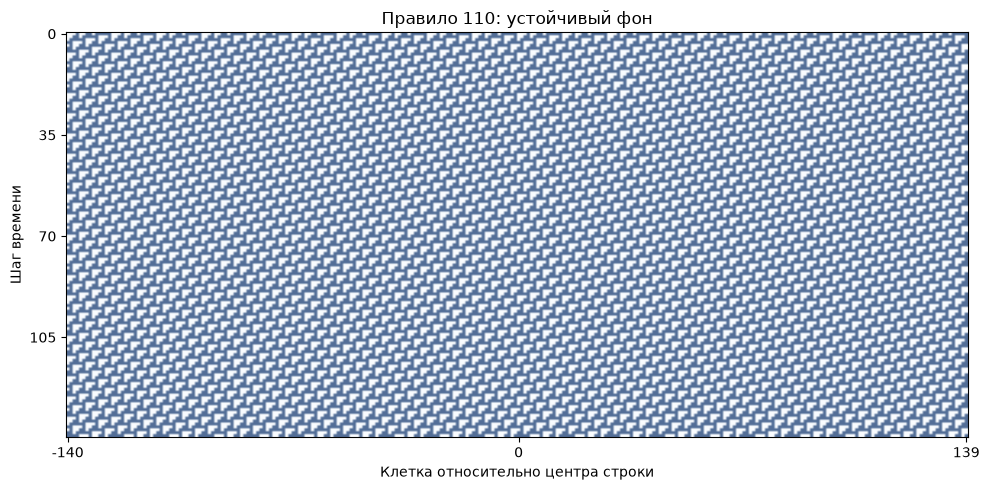

In [3]:
ETHER = "00010011011111"


def run_ca(initial, rows=220):
    """Запустить автомат на строке initial и сохранить историю."""
    ca = Cell1D(rule=110, n=rows, m=len(initial))
    ca.start_string(initial)
    ca.loop(ca.n - 1)
    return ca


def with_seed(seed, rows=220):
    """Вставить шаблон между двумя длинными участками фона."""
    return run_ca(ETHER * 40 + seed + ETHER * 40, rows)


def show_ca(ca, title, radius=140, ax=None, mark_defect=False):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    plt.sca(ax)
    center = ca.m // 2
    ca.draw(start=center - radius, end=center + radius)
    if mark_defect:
        # Подсветка нарушения фоновой периодичности помогает видеть траектории.
        a = ca.array[:, center - radius:center + radius]
        mask = np.zeros_like(a, dtype=bool)
        mask[:, :-14] = a[:, :-14] != a[:, 14:]
        ax.images[-1].set_alpha(0.25)
        ax.imshow(np.where(mask, 1.0, np.nan), cmap="Reds", vmin=0, vmax=1,
                  alpha=0.8, interpolation="none", aspect="auto")
    ax.set_aspect("auto")
    ax.set_xticks([0, radius, 2 * radius - 1], [-radius, 0, radius - 1])
    ax.set_yticks(range(0, ca.n, max(1, ca.n // 4)))
    ax.set_xlabel("Клетка относительно центра строки")
    ax.set_ylabel("Шаг времени")
    ax.set_title(title)


background = run_ca(ETHER * 80, rows=140)
center = background.m // 2
fragment = background.array[:, center - 140:center + 140]

spatial_period = next(
    p for p in range(1, 15)
    if np.array_equal(fragment[0, :-p], fragment[0, p:])
)
background_period = next(
    p for p in range(1, 15)
    if np.array_equal(fragment[0], fragment[p])
)
print("Пространственный период:", spatial_period, "клеток")
print("Временной период:", background_period, "шагов")
show_ca(background, "Правило 110: устойчивый фон")
plt.tight_layout()
plt.show()

### 2. Известные корабли и измерение движения

Вставим в середину фона три шаблона из статьи. «Корабль» — локализованная структура,
которая через некоторое время воспроизводится со сдвигом. При нулевом сдвиге это
неподвижная периодическая структура.

Период $T$ и сдвиг $d$ определяем по точному равенству
$a(t+T, x+d)=a(t,x)$ на всём исследуемом участке. Скорость $v=d/T$:
положительное значение означает движение вправо, отрицательное — влево.

Отбрасываем первые 80 шагов и проверяем равенство для 80 последовательных пар строк,
а не для одного случайного совпадения. Перебираем периоды до 42 и сдвиги от $-T$ до $T$.
Исследуемый участок содержит всю область, до которой могло дойти начальное возмущение
за время проверки. Чистый фон исключаем из результатов.

Чтобы траектории были лучше видны, на рисунках красным выделены позиции,
где нарушается пространственный период фона: $a(x)\ne a(x+14)$.
Это вспомогательная подсветка, исходные состояния клеток показаны бледно-синим.

Шаблон 0001110111: T=3, d=2, v=2/3 клеток/шаг
Шаблон 1001111: T=30, d=-8, v=-4/15 клеток/шаг
Шаблон 111: T=7, d=0, v=0 клеток/шаг


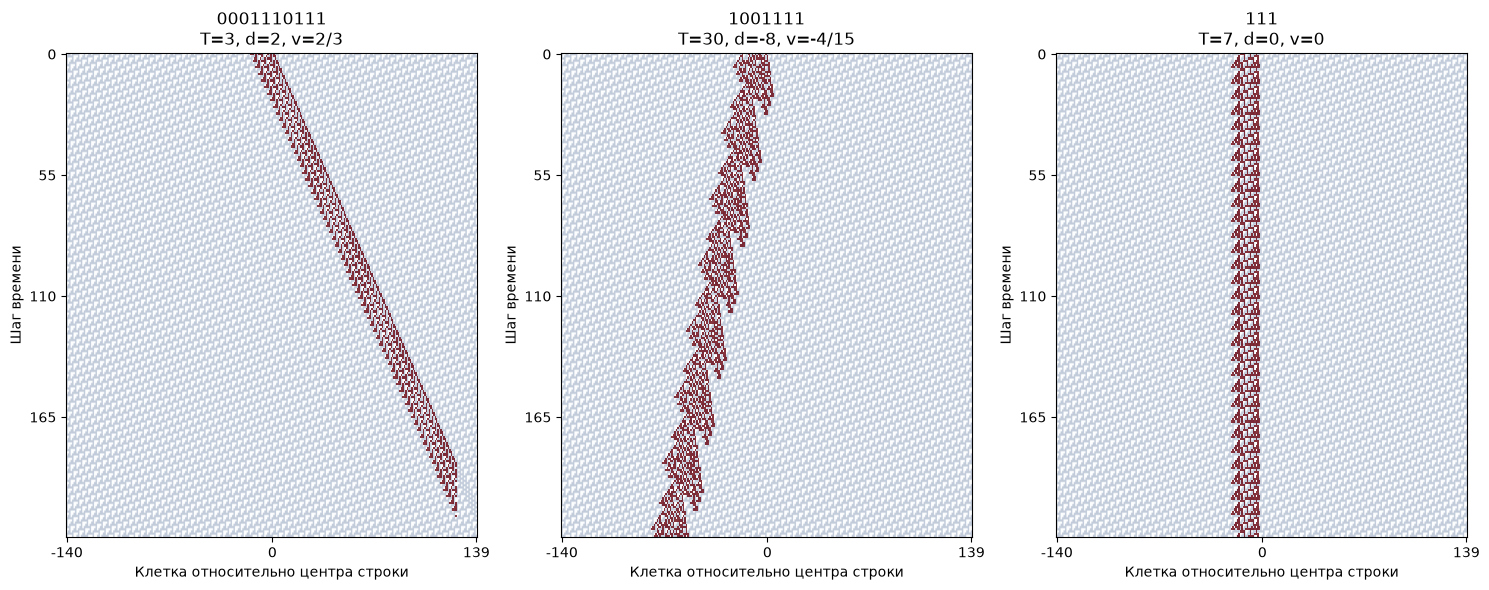

In [4]:
from fractions import Fraction


def find_motion(ca, burn=80, duration=80, max_period=42, radius=224):
    """Найти минимальный проверенный период и соответствующий сдвиг."""
    if burn + duration + max_period > ca.n:
        raise ValueError("Недостаточно строк истории для проверки")

    center = ca.m // 2
    lo, hi = center - radius, center + radius
    a = ca.array
    row = a[burn, lo:hi]

    # У чистого фона пространственный период равен 14.
    if np.array_equal(row[:-14], row[14:]):
        return None

    reference = a[burn:burn + duration, lo:hi]
    for period in range(1, max_period + 1):
        for shift in range(-period, period + 1):
            # Сначала быстрая проверка одной пары строк.
            if not np.array_equal(row, a[burn + period, lo + shift:hi + shift]):
                continue
            shifted = a[
                burn + period:burn + duration + period,
                lo + shift:hi + shift
            ]
            if np.array_equal(reference, shifted):
                return period, shift
    return None


known_seeds = ["0001110111", "1001111", "111"]
known_motion = []
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

for seed, ax in zip(known_seeds, axes):
    ca = with_seed(seed)
    motion = find_motion(ca)
    known_motion.append(motion)
    period, shift = motion
    velocity = Fraction(shift, period)
    print(f"Шаблон {seed}: T={period}, d={shift}, v={velocity} клеток/шаг")
    show_ca(ca, f"{seed}\nT={period}, d={shift}, v={velocity}",
            ax=ax, mark_defect=True)

plt.tight_layout()
plt.show()

### 3. Перебор восьмибитных шаблонов

Проверим все $2^8=256$ шаблонов, вставляя каждый между одинаковыми участками фона.
Сохраним те, для которых удалось подтвердить повторение со сдвигом.
Отсутствие результата означает только, что повторение не обнаружено при выбранных
времени наблюдения и максимальном периоде.

Для сравнения размеров используем явную численную меру: на каждой строке находим
позиции $x$, где $a(x)\ne a(x+14)$, и измеряем расстояние между крайними такими
позициями включительно. Берём максимум за один найденный период. Это **размах
нарушения фоновой периодичности**, а не число единиц и не общепринятая ширина корабля.

Одинаковые период и скорость не доказывают, что структуры одинаковы.
Некоторые найденные объекты могут быть связанными группами нескольких кораблей.

In [5]:
def defect_width(ca, period, burn=80, radius=224):
    """Максимальный размах нарушения 14-клеточной периодичности."""
    center = ca.m // 2
    widths = []
    for row in ca.array[burn:burn + period, center - radius:center + radius]:
        positions = np.flatnonzero(row[:-14] != row[14:])
        widths.append(int(positions[-1] - positions[0] + 1) if len(positions) else 0)
    return max(widths)


found = []
for number in range(2 ** 8):
    seed = f"{number:08b}"
    ca = with_seed(seed)
    motion = find_motion(ca)
    if motion is not None:
        period, shift = motion
        found.append({
            "seed": seed, "period": period, "shift": shift,
            "width": defect_width(ca, period)
        })

# Для каждой пары (период, сдвиг) выбираем самый широкий пример.
groups = {}
for item in found:
    key = (item["period"], item["shift"])
    groups.setdefault(key, []).append(item)

representatives = [max(items, key=lambda item: item["width"])
                   for key, items in sorted(groups.items())]
largest = max(found, key=lambda item: item["width"])

print(f"Проверено 256 шаблонов. Подтверждено периодических структур: {len(found)}.")
print("Различных пар (период, сдвиг):", len(groups))
print(f"{'Шаблон':<12}{'T':>5}{'d':>5}{'v':>9}{'Размах':>9}{'Примеров':>11}")
for item in representatives:
    p, d = item["period"], item["shift"]
    print(f"{item['seed']:<12}{p:>5}{d:>5}{str(Fraction(d, p)):>9}"
          f"{item['width']:>9}{len(groups[p, d]):>11}")

print("\nСамая большая структура среди перебранных шаблонов:")
print(f"шаблон {largest['seed']}, размах {largest['width']}, "
      f"T={largest['period']}, d={largest['shift']}, "
      f"v={Fraction(largest['shift'], largest['period'])}.")

Проверено 256 шаблонов. Подтверждено периодических структур: 84.
Различных пар (период, сдвиг): 5
Шаблон          T    d        v   Размах   Примеров
00100001        3    2      2/3       34          8
00000011        4   -2     -1/2       14         55
00001011        7    0        0       28         11
11101010       10    2      1/5       37          2
00001010       12   -6     -1/2       30          8

Самая большая структура среди перебранных шаблонов:
шаблон 11101010, размах 37, T=10, d=2, v=1/5.


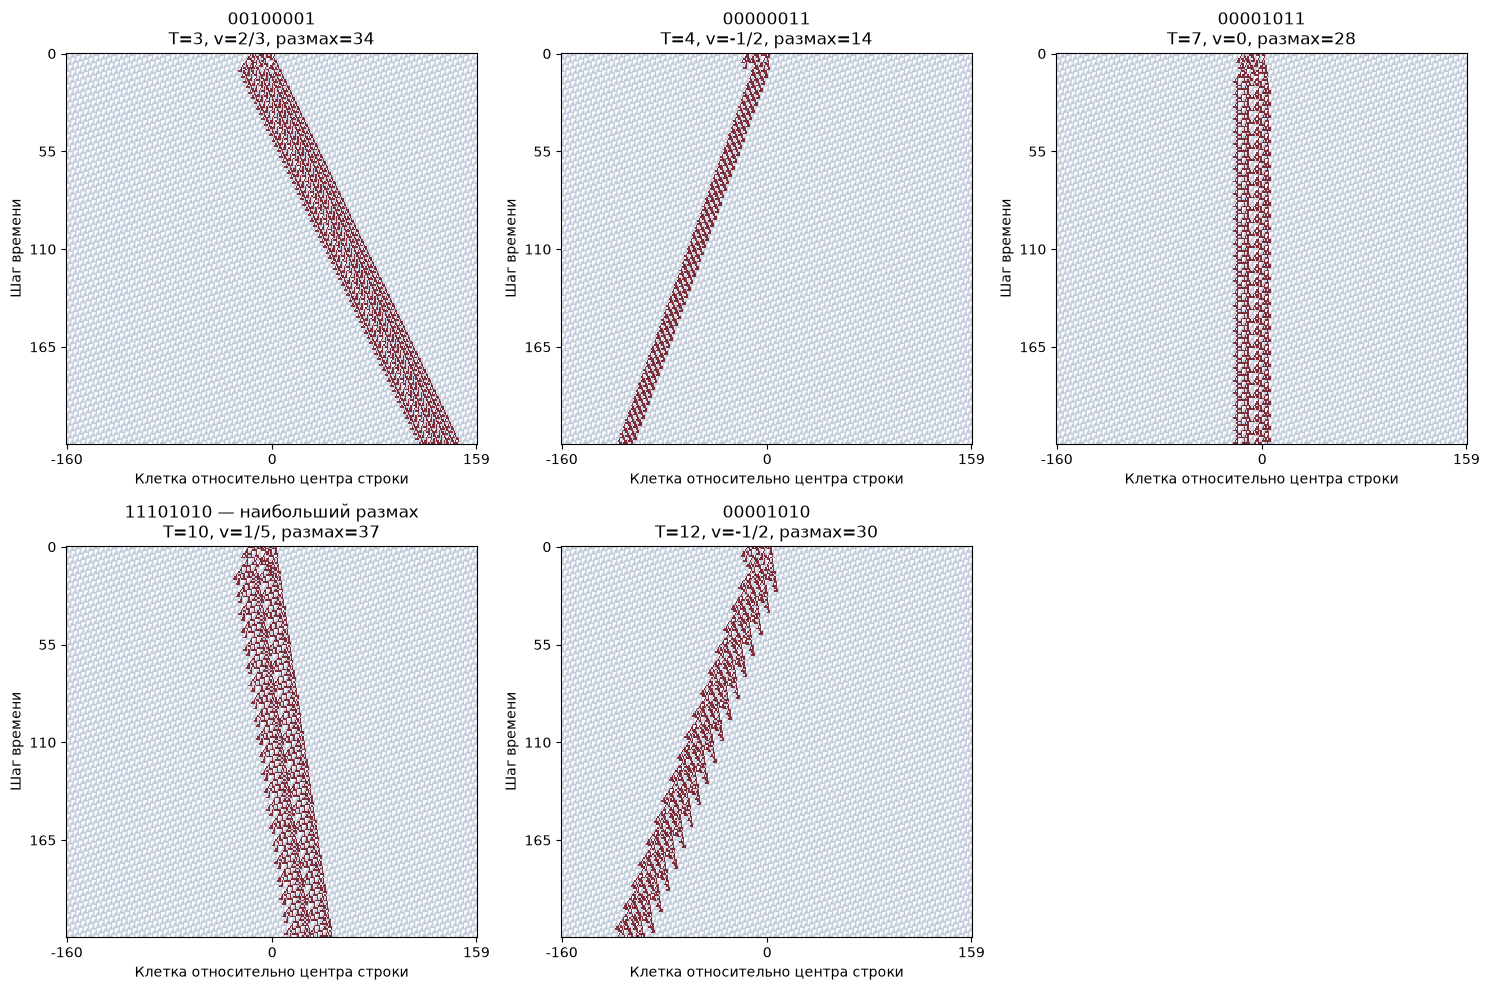

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for item, ax in zip(representatives, axes.flat):
    p, d = item["period"], item["shift"]
    label = " — наибольший размах" if item == largest else ""
    show_ca(
        with_seed(item["seed"]),
        f"{item['seed']}{label}\nT={p}, v={Fraction(d, p)}, размах={item['width']}",
        radius=160, ax=ax, mark_defect=True
    )
for ax in list(axes.flat)[len(representatives):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4. Столкновения

Шаблон `00000011`, найденный перебором, после переходного процесса даёт структуру,
движущуюся влево со скоростью $-1/2$. Поместим её справа от другого объекта:

1. слева корабль `0001110111`, движущийся вправо;
2. слева неподвижная структура `111`.

Между объектами оставляем восемь блоков фона. Этого достаточно, чтобы наблюдать
их отдельное движение до встречи. После столкновения заново измеряем период и сдвиг.

0001110111 + 00000011: после столкновения T=3, d=2, v=2/3 клеток/шаг
111 + 00000011: после столкновения T=10, d=2, v=1/5 клеток/шаг


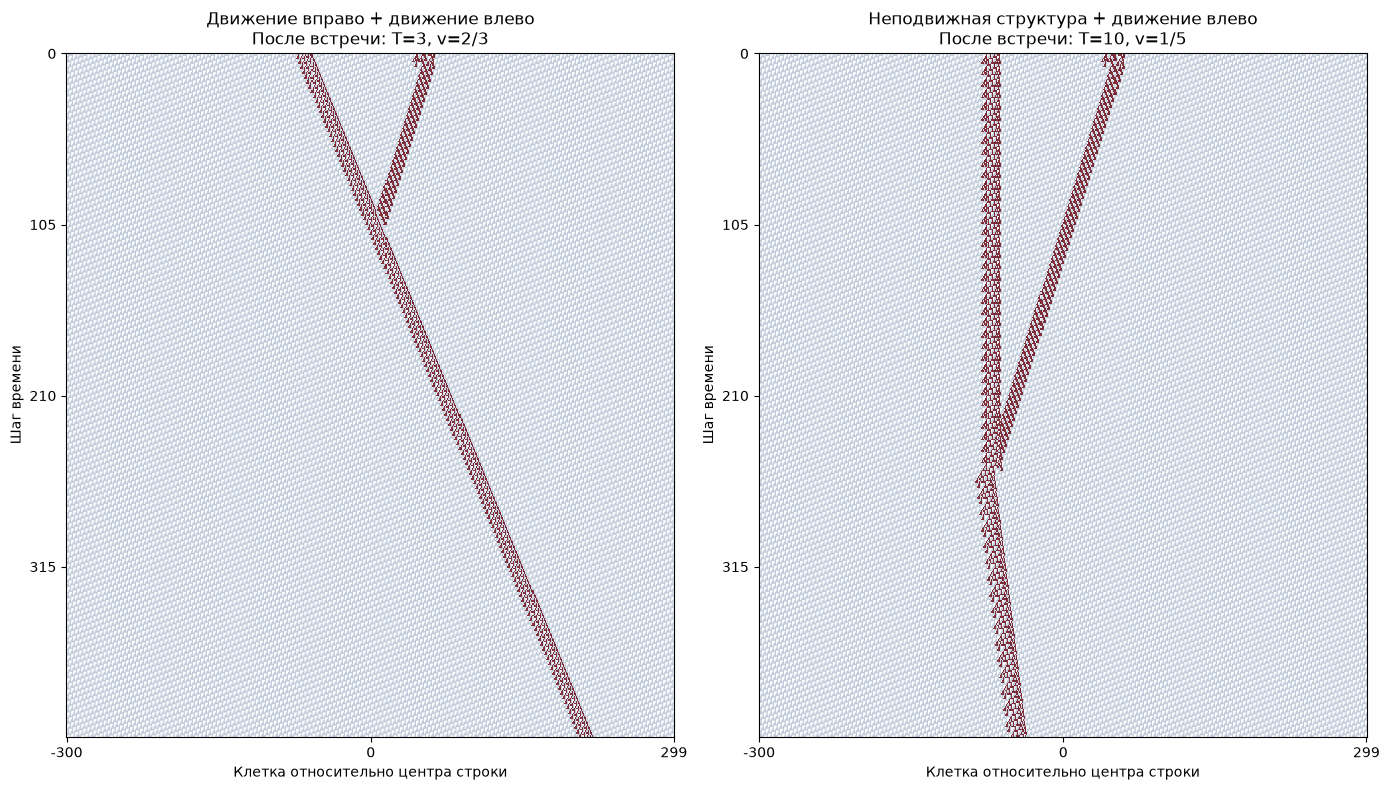

In [7]:
collision_cases = [
    ("0001110111", "00000011", "Движение вправо + движение влево"),
    ("111", "00000011", "Неподвижная структура + движение влево"),
]

collision_motion = []
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for (left_seed, right_seed, title), ax in zip(collision_cases, axes):
    initial = (ETHER * 60 + left_seed + ETHER * 8
               + right_seed + ETHER * 60)
    ca = run_ca(initial, rows=420)
    motion = find_motion(ca, burn=280, radius=300)
    collision_motion.append(motion)
    period, shift = motion
    velocity = Fraction(shift, period)
    print(f"{left_seed} + {right_seed}: после столкновения "
          f"T={period}, d={shift}, v={velocity} клеток/шаг")
    show_ca(ca, f"{title}\nПосле встречи: T={period}, v={velocity}",
            radius=300, ax=ax, mark_defect=True)

plt.tight_layout()
plt.show()

### Выводы

- Фон имеет пространственный период **14 клеток** и временной период **7 шагов**.
- Три примера из статьи дают $(T,d,v)=(3,2,2/3)$, $(30,-8,-4/15)$ и $(7,0,0)$.
  Таким образом, существуют структуры, движущиеся вправо, влево и остающиеся на месте.
- Среди 256 восьмибитных вставок для **84** подтверждено периодическое движение
  в выбранном окне наблюдения. Получено **5 разных пар периода и сдвига**, но это
  не означает, что найдено ровно пять разновидностей одиночных кораблей.
- Наибольший измеренный размах нарушения фона — **37** у вставки `11101010`:
  $T=10$, $d=2$, $v=1/5$. Это максимум только среди проверенных вставок,
  а не самый большой возможный корабль Правила 110; объект может быть составным.
- Столкновения не сводятся к независимому движению объектов. В первом опыте после
  встречи остаётся структура с $T=3$, $d=2$. Во втором неподвижная и леводвижущаяся
  структуры преобразуются в движущуюся вправо структуру с $T=10$, $d=2$.
  Эти результаты относятся к конкретным шаблонам, фазам и расстоянию между ними;
  для других начальных условий результат может отличаться.

In [8]:
# Самопроверка результатов описанных выше экспериментов.
assert spatial_period == 14
assert background_period == 7
assert known_motion == [(3, 2), (30, -8), (7, 0)]
assert len(found) == 84
assert len(groups) == 5
assert (largest["seed"], largest["width"]) == ("11101010", 37)
assert collision_motion == [(3, 2), (10, 2)]
print("Проверки упражнения 1 пройдены.")

Проверки упражнения 1 пройдены.


**Exercise:** The goal of this exercise is to implement a Turing machine.

1. Read about Turing machines at http://en.wikipedia.org/wiki/Turing_machine.

2. Write a class called `Turing` that implements a Turing machine.  For the action table, use the rules for a 3-state busy beaver.

3. Write a `draw` method that plots the state of the tape and the position and state of the head.  For one example of what that might look like, see http://mathworld.wolfram.com/TuringMachine.html.

**Упражнение:** Цель данного упражнения – реализация машины Тьюринга.

1. Прочтите о машинах Тьюринга на странице https://thinkcomplex.com/tm, http://en.wikipedia.org/wiki/Turing_machine.

2. Напишите класс с именем `Turing`, который реализует машину Тьюринга. Для таблицы действий используйте правила для усердного бобра с тремя состояниями.

3. Напишите класс с именем TuringViewer, который генерирует изображение, представляющее состояние ленты, а также положение и состояние головки. Пример того, как это может выглядеть, см. на странице https://thinkcomplex.com/turing, http://mathworld.wolfram.com/TuringMachine.html.

## Решение упражнения 2. Машина Тьюринга

Реализуем ленту с символами 0 и 1, головку и три рабочих состояния A, B, C.
Каждая команда читает символ, записывает новый, перемещает головку и меняет состояние.
Используем трёхсостоянийного усердного бобра, оставляющего 6 единиц за 14 шагов.
`HALT` обозначает остановку и не входит в три рабочих состояния.
Подробный разбор: [chap05_turing_explanation.md](chap05_turing_explanation.md).

In [2]:
class Turing:
    """Трёхсостоянийный усердный бобр на двоичной ленте."""

    rules = {
        # (состояние, прочитано): (записать, движение, новое состояние)
        ("A", 0): (1,  1, "B"),
        ("A", 1): (1,  1, "HALT"),
        ("B", 0): (0,  1, "C"),
        ("B", 1): (1,  1, "B"),
        ("C", 0): (1, -1, "C"),
        ("C", 1): (1, -1, "A"),
    }

    def __init__(self):
        self.tape = {}      # Позиция -> символ; отсутствующая клетка равна 0.
        self.head = 0
        self.state = "A"
        self.steps = 0
        self.history = []
        self.save_state()

    def save_state(self):
        """Сохранить снимок, не изменяющийся при дальнейшей работе."""
        self.history.append({
            "tape": self.tape.copy(),
            "head": self.head,
            "state": self.state,
            "step": self.steps,
        })

    def step(self):
        """Выполнить команду; вернуть False, если машина уже остановлена."""
        if self.state == "HALT":
            return False

        symbol = self.tape.get(self.head, 0)
        write, move, next_state = self.rules[self.state, symbol]
        self.tape[self.head] = write
        self.head += move
        self.state = next_state
        self.steps += 1
        self.save_state()
        return True

    def run(self, max_steps=1000):
        """Выполнить не более max_steps дополнительных команд до остановки."""
        for _ in range(max_steps):
            if self.state == "HALT":
                break
            self.step()
        if self.state != "HALT":
            raise RuntimeError("Машина не остановилась за заданное число шагов")
        return self.steps

In [3]:
class TuringViewer:
    """Показать историю ленты, положения и состояния головки."""

    def __init__(self, machine):
        self.machine = machine

    def draw(self):
        history = self.machine.history
        positions = [item["head"] for item in history]
        positions += [pos for item in history for pos in item["tape"]]
        left, right = min(positions) - 1, max(positions) + 1

        image = np.array([
            [item["tape"].get(pos, 0) for pos in range(left, right + 1)]
            for item in history
        ])

        _, ax = plt.subplots(figsize=(8, 7))
        ax.imshow(image, cmap="binary", vmin=0, vmax=1, alpha=0.6,
                  interpolation="nearest", aspect="auto",
                  extent=(left - 0.5, right + 0.5, len(history) - 0.5, -0.5))

        for row, item in enumerate(history):
            ax.scatter(item["head"], row, marker="s", s=230,
                       facecolors="none", edgecolors="tab:red")
            ax.text(item["head"], row, item["state"],
                    ha="center", va="center", color="tab:red", fontsize=10,
                    bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.3})

        ax.set_xticks(range(left, right + 1))
        ax.set_yticks(range(len(history)))
        ax.set_xticks(np.arange(left - 0.5, right + 1, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(history), 1), minor=True)
        ax.grid(which="minor", color="lightgray", linewidth=0.5)
        ax.tick_params(which="minor", length=0)
        ax.set_xlabel("Позиция на ленте")
        ax.set_ylabel("Количество выполненных шагов")
        ax.set_title("Усердный бобр: белый — 0, серый — 1; красный — головка")
        plt.tight_layout()
        return ax

Состояние: HALT
Выполнено шагов: 14
Единиц на ленте: 6
Положение головки: 2


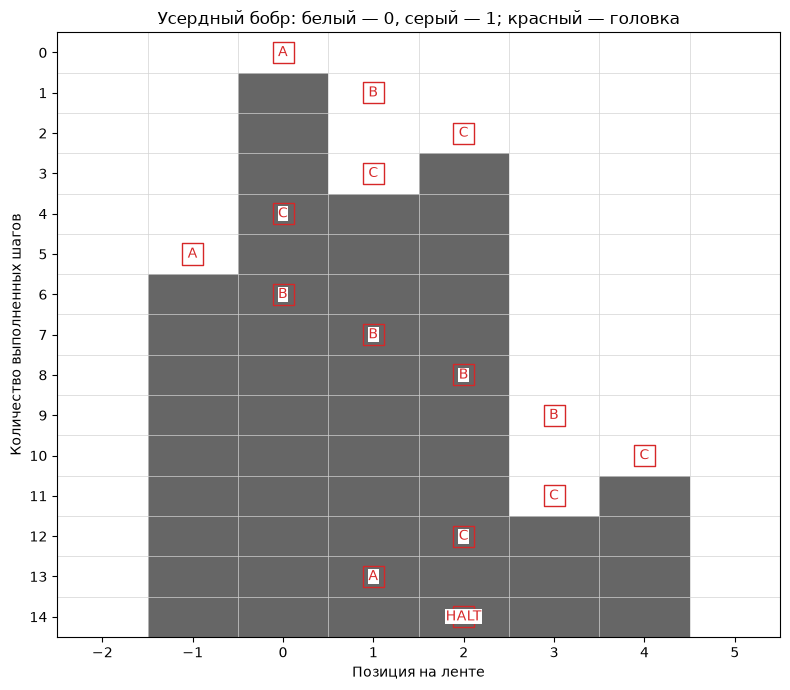

In [4]:
machine = Turing()
machine.run()

print("Состояние:", machine.state)
print("Выполнено шагов:", machine.steps)
print("Единиц на ленте:", sum(machine.tape.values()))
print("Положение головки:", machine.head)

viewer = TuringViewer(machine)
viewer.draw()
plt.show()

In [5]:
# Для выбранной таблицы ожидаем остановку за 14 шагов и 6 единиц.
assert machine.state == "HALT"
assert machine.steps == 14
assert sum(machine.tape.values()) == 6
assert len(machine.history) == 15  # Начальное состояние + 14 шагов.
assert machine.history[0]["tape"] == {}  # Снимки не изменились задним числом.

# После остановки команда step() уже ничего не меняет.
assert machine.step() is False
assert machine.steps == 14
print("Все проверки пройдены.")

Все проверки пройдены.


**Вывод:** машина остановилась после 14 команд, оставив на ленте 6 единиц.
`TuringViewer` показывает 15 строк: начальное состояние и состояние после каждой команды.
Красный квадрат и буква отмечают положение и состояние головки, включая `HALT`.
Это результат моделирования выбранной таблицы, а не самостоятельное доказательство
оптимальности усердного бобра.

**Exercise:** This exercise asks you to implement and test several PRNGs.
For testing, you will need to install 
`DieHarder`, which you can download from 
https://www.phy.duke.edu/~rgb/General/dieharder.php, or it
might be available as a package for your operating system.

1. Write a program that implements one of the linear congruential
generators described at http://en.wikipedia.org/wiki/Linear_congruential_generator}.
Test it using `DieHarder`.

2. Read the documentation of Python's `random` module.
What PRNG does it use?  Test it.

3. Implement a Rule 30 CA with a few hundred cells,
run it for as many time steps as you can in a reasonable amount
of time, and output the center column as a sequence of bits.
Test it.


**Упражнение:** В этом упражнении вас попросят внедрить и протестировать несколько генераторов псевдослучай-
ных чисел. Для тестирования вам потребуется установить `DieHarder`, который вы можете загрузить
по адресу https://thinkcomplex.com/dh, https://www.phy.duke.edu/~rgb/General/dieharder.php или он может быть доступен в виде пакета для вашей операционной системы.

1. Напишите программу, которая реализует один из линейных конгруэнтных генераторов, описанных на странице https://thinkcomplex.com/lcg, http://en.wikipedia.org/wiki/Linear_congruential_generator. Протестируйте ее с помощью `DieHarder`.

2. Прочитайте документацию к модулю Python `random`. Какой из генераторов псевдослучайных чисел он использует?
Протестируйте его.

3. Реализуйте Правило 30 с несколькими сотнями ячеек, запустите его на стольких временных шагах, сколько возможно за разумное время, и выведите центральный столбец в виде последовательности битов. Протестируйте его.


## Решение упражнения 3. Генераторы псевдослучайных чисел

Сравним линейный конгруэнтный генератор, Python `random` (Mersenne Twister)
и центральную клетку автомата Правила 30 шириной 501 с периодическими границами.
Все три генератора выдают 32-битные числа и сохраняют одинаковый объём данных.
У ЛКГ и Mersenne Twister начальное значение `seed=1`, у Правила 30 — одна единица в центре.
В Правиле 30 храним строку как биты одного целого числа, чтобы не сохранять
миллионы строк истории. Это оптимизация представления, не изменение правила.

Четыре ячейки: генераторы → проверки корректности → запись файлов → DieHarder.
Подробный разбор: [chap05_prng_explanation.md](chap05_prng_explanation.md).

In [2]:
import random
import re
import shlex
import shutil
import subprocess
from itertools import islice
from pathlib import Path
from time import perf_counter


def lcg_words(n, seed=1):
    """ЛКГ с параметрами Numerical Recipes: выдаёт n 32-битных чисел."""
    x = seed % (2 ** 32)
    for _ in range(n):
        x = (1664525 * x + 1013904223) % (2 ** 32)
        yield x


def mt_words(n, seed=1):
    """Модуль random использует Mersenne Twister (MT19937)."""
    rng = random.Random(seed)
    for _ in range(n):
        yield rng.getrandbits(32)


def rule30_bits(width=501):
    """Центральная клетка после каждого шага Правила 30; границы замкнуты."""
    if width < 3 or width % 2 == 0:
        raise ValueError("Ширина должна быть нечётной и не меньше 3")
    center = width // 2
    state = 1 << center             # Изначально одна единица в центре.
    mask = (1 << width) - 1         # Оставляем только width младших битов.
    while True:
        left = ((state << 1) & mask) | (state >> (width - 1))
        right = (state >> 1) | ((state & 1) << (width - 1))
        state = (left ^ (state | right)) & mask
        yield (state >> center) & 1


def rule30_words(n, width=501):
    """Объединить каждые 32 последовательных бита в одно число."""
    bits = rule30_bits(width)
    for _ in range(n):
        word = 0
        for _ in range(32):
            word = (word << 1) | next(bits)
        yield word


generators = {
    "lcg": lcg_words,
    "python_random": mt_words,
    "rule30": rule30_words,
}

In [3]:
# Независимая простая версия Правила 30 для проверки битовой реализации.
def reference_rule30(width, steps):
    row = [0] * width
    row[width // 2] = 1
    bits = []
    for _ in range(steps):
        row = [
            (30 >> (4 * row[(i - 1) % width] + 2 * row[i]
                    + row[(i + 1) % width])) & 1
            for i in range(width)
        ]
        bits.append(row[width // 2])
    return bits


assert list(lcg_words(3)) == [1015568748, 1586005467, 2165703038]
for width in (7, 17, 501):
    assert list(islice(rule30_bits(width), 80)) == reference_rule30(width, 80)

bits = list(islice(rule30_bits(width=17), 96))
expected = [int("".join(map(str, bits[i:i + 32])), 2)
            for i in range(0, 96, 32)]
assert list(rule30_words(3, width=17)) == expected

for name, factory in generators.items():
    sample = list(factory(5))
    assert sample == list(factory(5))  # Одинаковое начало -> одинаковый результат.
    assert all(0 <= word < 2 ** 32 for word in sample)
    print(name, "— первые 5 чисел:", sample)

print("Центральные биты Правила 30:",
      "".join(map(str, islice(rule30_bits(), 80))))
print("Проверки реализации пройдены. Это ещё не тесты случайности.")

lcg — первые 5 чисел: [1015568748, 1586005467, 2165703038, 3027450565, 217083232]
python_random — первые 5 чисел: [577090037, 2444712010, 3639700191, 3445702192, 3280387012]
rule30 — первые 5 чисел: [3112904540, 3938659159, 3789731877, 2385956881, 4149099232]
Центральные биты Правила 30: 10111001100010110010011101011100111010101100001100101011010101111110000111100010
Проверки реализации пройдены. Это ещё не тесты случайности.


In [4]:
N_WORDS = 2 ** 24  # 64 МиБ на генератор для коротких тестов DieHarder.
DATA_DIR = Path("data/prng")
DATA_DIR.mkdir(parents=True, exist_ok=True)


def write_words(path, words, block_size=16384):
    """Записать uint32 без заголовка, в порядке байтов текущей машины."""
    words = iter(words)
    with path.open("wb") as stream:
        while block := list(islice(words, block_size)):
            np.asarray(block, dtype="=u4").tofile(stream)


files = {}
print(f"{'Генератор':<16}{'Чисел':>10}{'МиБ':>8}{'Доля единиц':>15}{'Секунд':>10}")
for name, factory in generators.items():
    path = DATA_DIR / f"{name}.bin"
    started = perf_counter()
    write_words(path, factory(N_WORDS))
    elapsed = perf_counter() - started
    assert path.stat().st_size == 4 * N_WORDS
    assert np.fromfile(path, dtype="=u4", count=5).tolist() == list(factory(5))
    data = path.read_bytes()
    fraction = sum(byte.bit_count() for byte in data) / (8 * len(data))
    files[name] = path
    print(f"{name:<16}{N_WORDS:>10}{len(data) / 2 ** 20:>8.1f}"
          f"{fraction:>15.6f}{elapsed:>10.2f}")

print("\nУ Правила 30 выполнено", 32 * N_WORDS, "шагов при ширине 501.")
print("Близость доли единиц к 0.5 не доказывает случайность последовательности.")

Генератор            Чисел     МиБ    Доля единиц    Секунд


lcg               16777216    64.0       0.500017      4.26


python_random     16777216    64.0       0.499986      2.74


rule30            16777216    64.0       0.499955    355.55

У Правила 30 выполнено 536870912 шагов при ширине 501.
Близость доли единиц к 0.5 не доказывает случайность последовательности.


In [5]:
dieharder = shutil.which("dieharder")
TEST_IDS = (0, 2)  # Diehard Birthdays и Binary Rank 32x32.
MIN_TEST_BYTES = 64 * 2 ** 20

commands = [
    (name, test_id, [dieharder or "dieharder", "-g", "201", "-f", str(path),
                     "-d", str(test_id), "-p", "5"])
    for name, path in files.items() for test_id in TEST_IDS
]

if dieharder is None:
    print("DieHarder не установлен: статистические тесты НЕ выполнены.")
    print("После установки увеличьте N_WORDS до 2**24 (64 МиБ на генератор),")
    print("повторите генерацию и выполните эту ячейку снова.")
elif any(path.stat().st_size < MIN_TEST_BYTES for path in files.values()):
    print("Тесты НЕ запущены: демонстрационные файлы слишком малы.")
    print("Установите N_WORDS = 2**24 и повторите две последние ячейки.")
    print("64 МиБ — стартовый объём для выбранных коротких тестов, не гарантия:")
    print("после запуска всё равно проверьте сообщения о повторном чтении файла.")
else:
    for name, test_id, command in commands:
        log = DATA_DIR / f"{name}_test_{test_id}.txt"
        try:
            result = subprocess.run(command, capture_output=True, text=True,
                                    timeout=180, check=False)
            output = result.stdout + "\n" + result.stderr
            log.write_text(output, encoding="utf-8")
            rewinds = [int(value) for value in
                       re.findall(r"rewound\s+(\d+)\s+times", output, re.I)]
            assessments = re.findall(r"\b(?:PASSED|WEAK|FAILED)\b", output)
            if result.returncode != 0:
                status = f"ошибка запуска, код {result.returncode}"
            elif any(value > 0 for value in rewinds):
                status = "файл читался повторно: оценку нельзя считать надёжной"
            elif not assessments:
                status = "оценка не найдена — смотрите журнал"
            else:
                status = ", ".join(assessments)
                if not rewinds:
                    status += "; сведения о повторном чтении не найдены — проверьте журнал"
            print(f"{name}, тест {test_id}: {status}; журнал: {log}")
        except subprocess.TimeoutExpired:
            log.write_text("Тест прерван по лимиту 180 секунд; оценки нет.\n",
                           encoding="utf-8")
            print(f"{name}, тест {test_id}: превышено время; оценки нет.")

print("\nКоманды для ручного запуска (после подготовки достаточного объёма данных):")
for _, _, command in commands:
    print(shlex.join(command))

lcg, тест 0: PASSED; сведения о повторном чтении не найдены — проверьте журнал; журнал: data/prng/lcg_test_0.txt


lcg, тест 2: PASSED; сведения о повторном чтении не найдены — проверьте журнал; журнал: data/prng/lcg_test_2.txt
python_random, тест 0: PASSED; сведения о повторном чтении не найдены — проверьте журнал; журнал: data/prng/python_random_test_0.txt


python_random, тест 2: WEAK; сведения о повторном чтении не найдены — проверьте журнал; журнал: data/prng/python_random_test_2.txt
rule30, тест 0: PASSED; сведения о повторном чтении не найдены — проверьте журнал; журнал: data/prng/rule30_test_0.txt


rule30, тест 2: PASSED; сведения о повторном чтении не найдены — проверьте журнал; журнал: data/prng/rule30_test_2.txt

Команды для ручного запуска (после подготовки достаточного объёма данных):
/usr/bin/dieharder -g 201 -f data/prng/lcg.bin -d 0 -p 5
/usr/bin/dieharder -g 201 -f data/prng/lcg.bin -d 2 -p 5
/usr/bin/dieharder -g 201 -f data/prng/python_random.bin -d 0 -p 5
/usr/bin/dieharder -g 201 -f data/prng/python_random.bin -d 2 -p 5
/usr/bin/dieharder -g 201 -f data/prng/rule30.bin -d 0 -p 5
/usr/bin/dieharder -g 201 -f data/prng/rule30.bin -d 2 -p 5


### Выводы и фактические результаты DieHarder

- Реализован ЛКГ $x_{n+1}=(1664525x_n+1013904223)\bmod 2^{32}$.
  Его младшие биты имеют короткие периоды; большой период всей последовательности
  не означает хороших статистических свойств.
- Python `random` использует Mersenne Twister и воспроизводит последовательность
  при одинаковом `seed`. Он не предназначен для криптографии.
- Правило 30 проверено по независимой реализации таблицы переходов. При ширине 501
  выполнено $2^{29}=536\,870\,912$ шагов; каждые 32 центральных бита образуют число.
- Сохранены три файла по 64 МиБ. Выполнены настоящие тесты DieHarder 3.31.1:
  Birthdays и Binary Rank 32x32, с параметром `-p 5` для каждого генератора.
  Сообщений о повторном чтении файлов с ненулевым счётчиком не обнаружено.
  Полные журналы находятся в `data/prng/*_test_*.txt`.

| Генератор | Тест | p-value | Оценка |
|---|---|---:|---|
| lcg | diehard_birthdays | 0.99320508 | PASSED |
| lcg | diehard_rank_32x32 | 0.76185391 | PASSED |
| python_random | diehard_birthdays | 0.97415423 | PASSED |
| python_random | diehard_rank_32x32 | 0.99755408 | WEAK |
| rule30 | diehard_birthdays | 0.35440977 | PASSED |
| rule30 | diehard_rank_32x32 | 0.96042416 | PASSED |

Это ограниченная проверка двумя тестами, а не вся батарея DieHarder.
`PASSED` означает, что конкретный тест не обнаружил значимого отклонения,
а не доказательство идеальной случайности или криптографической безопасности.
Для `WEAK` и `FAILED` следует дополнительно проверить новые участки последовательности
и другие начальные состояния. Выводы относятся только к указанным настройкам и данным.